In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path

In [3]:
COUNTRY = "DE"
START_DATE = "20210101"
END_DATE = "20260101"

In [4]:
MIN_READINGS_PER_HOUR = 2      # of 4 quarter-hours; fewer -> that hour is NaN

In [5]:
grid_load_path = os.path.join("..", "data", f"grid_load_{COUNTRY}_{START_DATE}_{END_DATE}.csv")
generation_path = os.path.join("..", "data", f"generation_{COUNTRY}_LU_{START_DATE}_{END_DATE}.csv")
weather_path = os.path.join("..", "data", f"weather_{COUNTRY}_{START_DATE}_{END_DATE}.csv")

In [6]:
def read_csv_utc(path):
    """Read a CSV with a 'time' column into a DataFrame with UTC-aware timestamps."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"{path} not found - run extraction/extract.py first.")
    df = pd.read_csv(path)
    df["time"] = pd.to_datetime(df["time"], utc=True)
    return df


## Inspect Grid Load (MW) data

In [66]:
grid_load_df = read_csv_utc(grid_load_path)
grid_load_df.head()

,time,Total_Load_MW
0,2020-12-31 23:00:00+00:00,44973.37
1,2020-12-31 23:15:00+00:00,44762.26
2,2020-12-31 23:30:00+00:00,44418.71
3,2020-12-31 23:45:00+00:00,44123.45
4,2021-01-01 00:00:00+00:00,43497.26


In [7]:
grid_load_df["Total_Load_MW"].isna().sum() / len(grid_load_df) * 100

np.float64(0.0)

In [8]:
(grid_load_df["Total_Load_MW"] <= 0).sum() / len(grid_load_df) * 100

np.float64(0.0)

In [7]:
def to_hourly(df, min_readings=MIN_READINGS_PER_HOUR):
    """
    15-minute frame (with a UTC 'time' column) -> hourly frame indexed by hour start.
    Each value is the mean of the available readings in that hour; hours with fewer
    than `min_readings` valid readings are NaN. Every hour between the first and last
    timestamp is present in the result.
    """
    r = df.set_index("time").resample("1h")
    return r.mean().where(r.count() >= min_readings)

In [67]:
hourly = to_hourly(grid_load_df)
print(f"resampled to {len(hourly):,} hourly rows, {int(hourly['Total_Load_MW'].isna().sum())} NaN hours")

resampled to 43,824 hourly rows, 0 NaN hours


In [36]:
hourly.describe()

,Total_Load_MW
count,43824.000000
mean,54230.549396
std,9499.373086
min,30902.685000
25%,46458.332500
50%,54213.822500
75%,61467.576875
max,81319.465000


<Axes: xlabel='Total_Load_MW', ylabel='Count'>

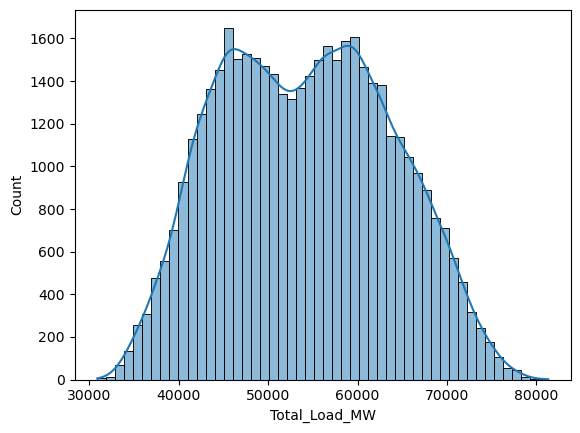

In [12]:
sns.histplot(hourly["Total_Load_MW"], bins=50, kde=True)

In [37]:
hourly.head(2)

,Total_Load_MW
time,
2020-12-31 23:00:00+00:00,44569.4475
2021-01-01 00:00:00+00:00,42806.0900


In [8]:
def identify_spikes(hourly_df):
    SPIKE_N_SIGMAS = 4
    col = "Total_Load_MW"
    s = hourly_df[col]
    dev = s - 0.5 * (s.shift(1) + s.shift(-1))
    sigma = 1.4826 * (dev - dev.median()).abs().median()
    adev = dev.abs().fillna(0)
    is_peak = (adev >= adev.shift(1, fill_value=0)) & (adev >= adev.shift(-1, fill_value=0))
    spikes = (adev > SPIKE_N_SIGMAS * sigma) & is_peak
    sns.histplot(adev, bins=50, kde=True)
    # hourly.loc[spikes, col] = np.nan
    print(f"  {int(spikes.sum())} spike hours set to NaN "
          f"(threshold {SPIKE_N_SIGMAS * sigma:,.0f} MW)")
    return spikes

  33 spike hours set to NaN (threshold 2,602 MW)


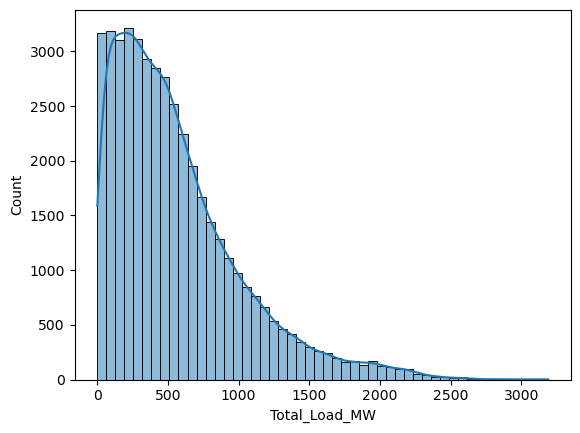

In [69]:
spikes = identify_spikes(hourly)

#### Absolute deviation distribution (high values = sudden peaks in load)

In [9]:
def check_spike_hours(hourly_df, spikes):
    region = 'Europe/Berlin'
    spike_hours = hourly_df.index[spikes].tz_convert(region).hour
    print(f"  {len(spike_hours)} spike hours:")
    sns.histplot(spike_hours, bins=24, discrete=True)

  33 spike hours:


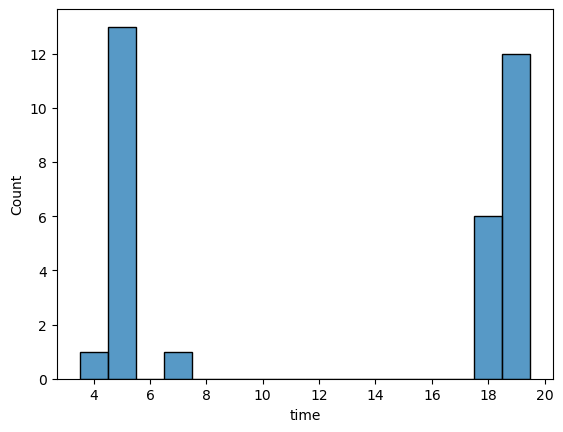

In [40]:
check_spike_hours(hourly, spikes)

#### Spike hours are in early morning or evening, logical behaviour, no filtering needed.

In [42]:
from scipy import stats
from sklearn.mixture import GaussianMixture

def fit_normal(hourly_df):
    os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count())
    x = hourly_df["Total_Load_MW"].dropna().to_numpy()
    grid = np.linspace(x.min(), x.max(), 500)

    # 1) single normal
    mu, sd = stats.norm.fit(x)

    # 2) mixtures of 1..4 normals, compared by BIC (lower = better)
    gmms = {k: GaussianMixture(k, n_init=5, random_state=0).fit(x.reshape(-1, 1)) for k in range(1, 5)}
    for k, g in gmms.items():
        print(f"k={k}: BIC={g.bic(x.reshape(-1, 1)):,.0f}")

    g = gmms[2]
    w, m, s = g.weights_, g.means_.ravel(), np.sqrt(g.covariances_.ravel())
    for i in np.argsort(m):
        print(f"weight={w[i]:.2f}  mean={m[i]:,.0f} MW  std={s[i]:,.0f} MW")

    fig, ax = plt.subplots(figsize=(10, 5))
    sns.histplot(x, bins=60, stat="density", color="lightgray", edgecolor="white", ax=ax, label="data")
    ax.plot(grid, stats.norm.pdf(grid, mu, sd), "r--", lw=2, label=f"single normal (mean {mu:,.0f}, std {sd:,.0f})")
    ax.plot(grid, np.exp(g.score_samples(grid.reshape(-1, 1))), "b-", lw=2, label="mixture of 2 normals")
    for i in np.argsort(m):  # each component on its own
        ax.plot(grid, w[i] * stats.norm.pdf(grid, m[i], s[i]), "b:", lw=1.2)
    ax.set_xlabel("Total load (MW)"); ax.set_ylabel("density"); ax.legend()

k=1: BIC=927,154
k=2: BIC=924,259
k=3: BIC=923,996
k=4: BIC=923,995
weight=0.49  mean=46,514 MW  std=5,473 MW
weight=0.51  mean=61,520 MW  std=6,148 MW


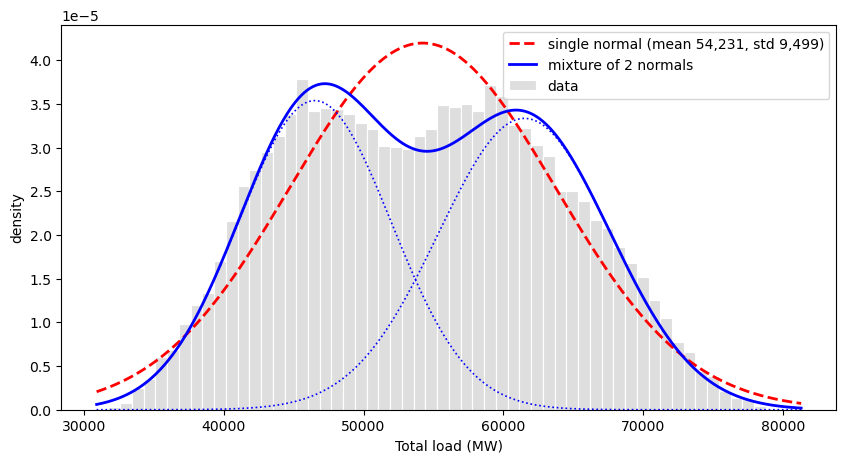

In [44]:
fit_normal(hourly)

#### Distribution of Load Data can be modelled as mixture of 2 Gaussians (normal distributions)

## Inspect Generation Data

In [71]:
generation_df = read_csv_utc(generation_path)
generation_df.head()

,time,Fossil_Oil_Consumption_MW,Hydro_Pumped_Storage_Consumption_MW,Hydro_Water_Reservoir_Consumption_MW,Biomass_MW,Fossil_Brown_coal_Lignite_MW,Fossil_Gas_MW,Fossil_Hard_coal_MW,Fossil_Oil_MW,Geothermal_MW,...,Other_renewable_MW,Solar_MW,Waste_MW,Wind_Offshore_MW,Wind_Onshore_MW,Other_MW,Solar_Consumption_MW,Wind_Onshore_Consumption_MW,Other_renewable_Consumption_MW,Fossil_Coal_derived_gas_MW
0,2020-12-31 23:00:00+00:00,0.15,317.95,NaN,4527.80,11594.00,6882.77,3749.30,404.34,30.96,...,183.73,1.25,791.99,339.92,4212.99,454.64,NaN,NaN,NaN,NaN
1,2020-12-31 23:15:00+00:00,0.11,329.83,NaN,4515.63,11618.47,6948.63,3487.60,406.01,30.92,...,181.02,1.24,792.74,352.09,4072.20,454.12,NaN,NaN,NaN,NaN
2,2020-12-31 23:30:00+00:00,0.02,433.59,NaN,4511.88,11616.99,6956.16,3316.50,405.68,31.01,...,181.24,1.23,784.92,404.98,3793.48,454.06,NaN,NaN,NaN,NaN
3,2020-12-31 23:45:00+00:00,0.06,470.58,NaN,4507.68,11604.87,6934.87,3220.69,403.50,31.06,...,181.60,1.19,778.50,435.38,3669.00,454.09,NaN,NaN,NaN,NaN
4,2021-01-01 00:00:00+00:00,0.02,230.84,NaN,4488.85,11644.27,6739.73,3140.24,405.68,31.02,...,182.07,1.32,786.86,422.82,3686.08,454.01,NaN,NaN,NaN,NaN


In [10]:
def check_nan_columns(df):
    rows = []
    for c in df.columns:
        if c == "time":
            continue
        s = df[c]
        v = s.dropna()
        rows.append({
            "column": c,
            "nan_%": round(100 * s.isna().mean(), 1),
            "min": v.min(),
            "max": v.max(),
        })
    print(pd.DataFrame(rows).sort_values("nan_%").to_string(index=False))

In [73]:
check_nan_columns(generation_df)

                              column  nan_%     min        max
            Hydro_Water_Reservoir_MW    0.0    0.04  1115.1500
                            Waste_MW    0.0  249.16  1015.2800
                            Solar_MW    0.0    0.16 53176.2200
                  Other_renewable_MW    0.0   41.88   197.8800
                            Other_MW    0.0   60.08   519.4700
   Hydro_Run_of_river_and_pondage_MW    0.0  786.17  2368.1000
             Hydro_Pumped_Storage_MW    0.0    0.00  8387.0600
                    Wind_Offshore_MW    0.0    0.00  8367.5550
                       Geothermal_MW    0.0    4.34    36.2734
                 Fossil_Hard_coal_MW    0.0  131.48 15857.3000
                       Fossil_Gas_MW    0.0 1255.00 20270.3100
        Fossil_Brown_coal_Lignite_MW    0.0 1869.43 17200.7700
                          Biomass_MW    0.0 3084.20  5295.3700
 Hydro_Pumped_Storage_Consumption_MW    0.0    0.00  8189.2700
                       Fossil_Oil_MW    0.0   36.98  13

In [74]:
hourly_generation = to_hourly(generation_df)

#### For nuclear generation data, last Nan value -> 0 MW since Germany closed its last nuclear plant in 2023

In [75]:
c = 'Nuclear_MW'
last = hourly_generation[c].last_valid_index()
if last is not None:
    after = hourly_generation.index > last
    hourly_generation.loc[after, c] = 0.0
    print(f"  {c}: {int(after.sum())} NaN hours after {last:%Y-%m-%d %H:%M} set to 0")

  Nuclear_MW: 23785 NaN hours after 2023-04-15 21:00 set to 0


In [76]:
hourly_generation['Nuclear_MW'].isna().sum() / len(hourly_generation) * 100

np.float64(0.0)

In [11]:
def _drop_sparse_columns(df, max_nan_pct=10):
    if "time" in df.columns:
        df = df.drop(columns=["time"])
    nan_pct = df.isna().mean() * 100
    sparse = nan_pct[nan_pct > max_nan_pct]
    for col, pct in sparse.items():
        if col == 'Nuclear_MW':
            print('Skip Nuclear_MW column with NaN percentage:', pct)
            continue
        print(f"  dropped column {col}: {pct:.1f}% NaN (limit {max_nan_pct}%)")
    return df.drop(columns=sparse.index, errors='ignore')

In [78]:
hourly_generation = _drop_sparse_columns(hourly_generation, max_nan_pct=10)
check_nan_columns(hourly_generation)

  dropped column Fossil_Oil_Consumption_MW: 98.2% NaN (limit 10%)
  dropped column Hydro_Water_Reservoir_Consumption_MW: 100.0% NaN (limit 10%)
  dropped column Solar_Consumption_MW: 13.6% NaN (limit 10%)
  dropped column Wind_Onshore_Consumption_MW: 13.6% NaN (limit 10%)
  dropped column Other_renewable_Consumption_MW: 100.0% NaN (limit 10%)
  dropped column Fossil_Coal_derived_gas_MW: 40.0% NaN (limit 10%)
                             column  nan_%        min         max
Hydro_Pumped_Storage_Consumption_MW    0.0    0.02000  8102.08250
                   Wind_Offshore_MW    0.0    0.00000  8278.07300
                           Waste_MW    0.0  250.93750  1014.96750
                           Solar_MW    0.0    0.20250 52466.20500
                 Other_renewable_MW    0.0   46.39750   196.52750
                         Nuclear_MW    0.0    0.00000  8204.78500
           Hydro_Water_Reservoir_MW    0.0    0.97000  1029.96500
                    Wind_Onshore_MW    0.0   47.19500 48682.

## Inspect Weather Open Meteo Data

In [12]:
weather_df = read_csv_utc(weather_path)
weather_df.head()

,time,location,temperature_2m,apparent_temperature,relative_humidity_2m,precipitation,cloud_cover,shortwave_radiation,wind_speed_10m,wind_speed_100m
0,2020-12-31 23:00:00+00:00,Berlin,1.6,-1.9,88,0.0,100,0.0,2.66,5.74
1,2021-01-01 00:00:00+00:00,Berlin,0.5,-2.7,94,0.0,99,0.0,1.97,4.87
2,2021-01-01 01:00:00+00:00,Berlin,0.5,-2.6,94,0.0,91,0.0,1.75,4.49
3,2021-01-01 02:00:00+00:00,Berlin,0.1,-3.0,95,0.0,99,0.0,1.75,4.57
4,2021-01-01 03:00:00+00:00,Berlin,0.6,-2.5,94,0.0,98,0.0,1.75,4.16


In [80]:
weather_df.describe()

,temperature_2m,apparent_temperature,relative_humidity_2m,precipitation,cloud_cover,shortwave_radiation,wind_speed_10m,wind_speed_100m
count,350592.000000,350592.000000,350592.000000,350592.000000,350592.000000,350592.000000,350592.000000,350592.000000
mean,10.905003,8.508784,76.693453,0.101088,67.160722,135.538449,3.433603,5.839397
std,7.603458,9.052912,16.314173,0.411964,39.438859,208.618118,1.944430,3.019222
min,-16.800000,-22.300000,11.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5.200000,1.400000,67.000000,0.000000,27.000000,0.000000,2.020000,3.660000
50%,10.600000,7.900000,81.000000,0.000000,94.000000,6.000000,3.040000,5.540000
75%,16.500000,15.300000,90.000000,0.000000,100.000000,211.000000,4.480000,7.600000
max,38.900000,38.900000,100.000000,16.900000,100.000000,939.000000,17.660000,27.510000


In [13]:
check_nan_columns(weather_df)

              column  nan_%    min       max
            location    0.0 Berlin Stuttgart
      temperature_2m    0.0  -16.8      38.9
apparent_temperature    0.0  -22.3      38.9
relative_humidity_2m    0.0     11       100
       precipitation    0.0    0.0      16.9
         cloud_cover    0.0      0       100
 shortwave_radiation    0.0    0.0     939.0
      wind_speed_10m    0.0    0.0     17.66
     wind_speed_100m    0.0    0.0     27.51


In [14]:
weather_df['location'].unique()

array(['Berlin', 'Cologne', 'Frankfurt', 'Hamburg', 'Hannover', 'Husum',
       'Munich', 'Stuttgart'], dtype=object)

<Axes: xlabel='temperature_2m', ylabel='Count'>

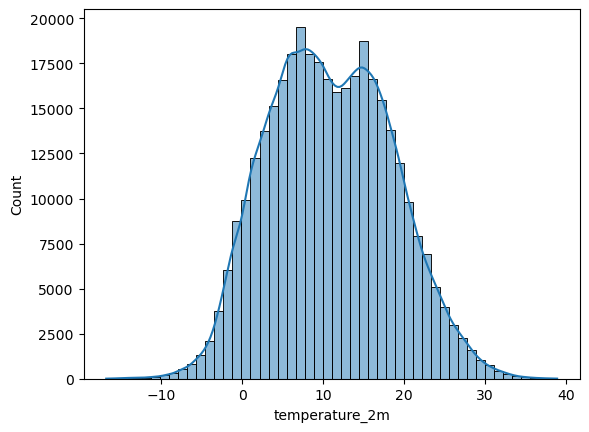

In [14]:
sns.histplot(weather_df['temperature_2m'], bins=50, kde=True)

<Axes: xlabel='apparent_temperature', ylabel='Count'>

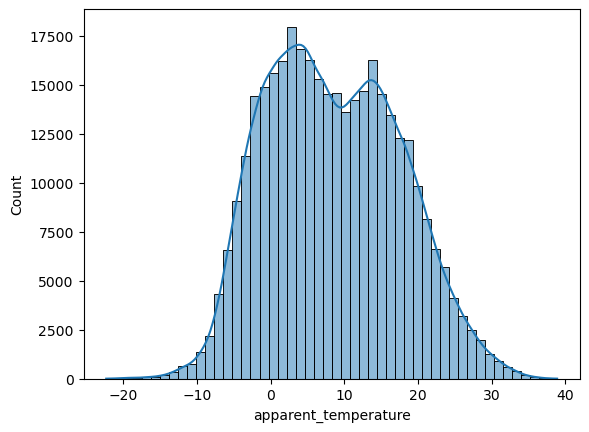

In [15]:
sns.histplot(weather_df['apparent_temperature'], bins=50, kde=True)

<Axes: ylabel='Count'>

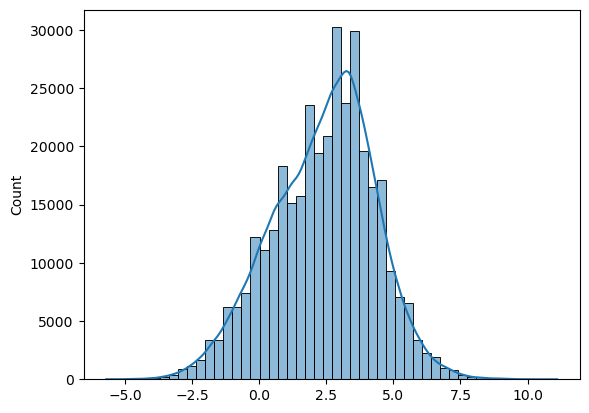

In [16]:
sns.histplot(weather_df['temperature_2m'] - weather_df['apparent_temperature'], bins=50, kde=True)

<Axes: xlabel='shortwave_radiation', ylabel='Count'>

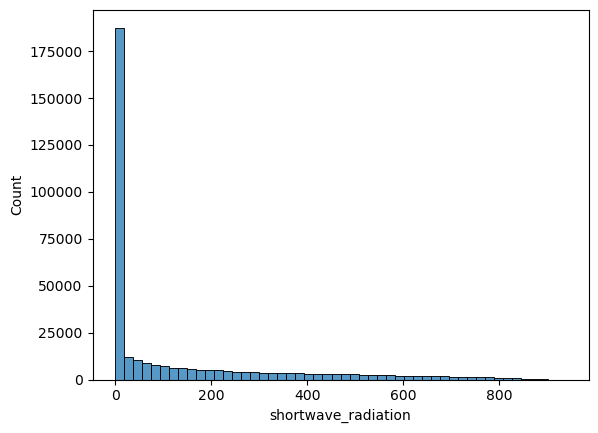

In [18]:
sns.histplot(weather_df['shortwave_radiation'], bins=50, kde=False)

<Axes: xlabel='wind_speed_10m', ylabel='Count'>

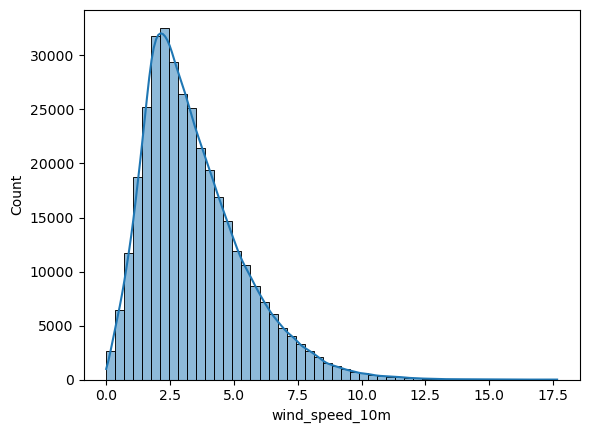

In [20]:
sns.histplot(weather_df['wind_speed_10m'], bins=50, kde=True)

<Axes: xlabel='wind_speed_100m', ylabel='Count'>

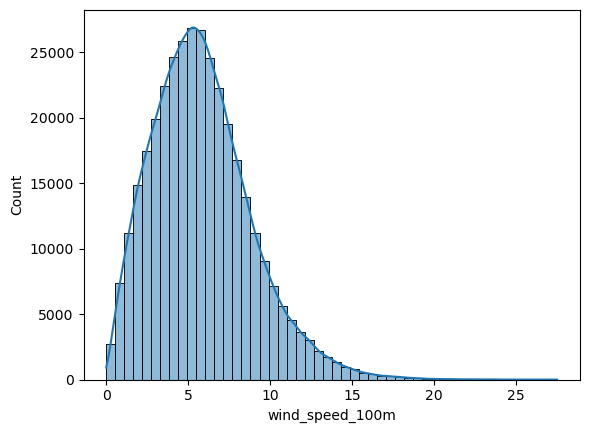

In [21]:
sns.histplot(weather_df['wind_speed_100m'], bins=50, kde=True)

<Axes: xlabel='precipitation', ylabel='Count'>

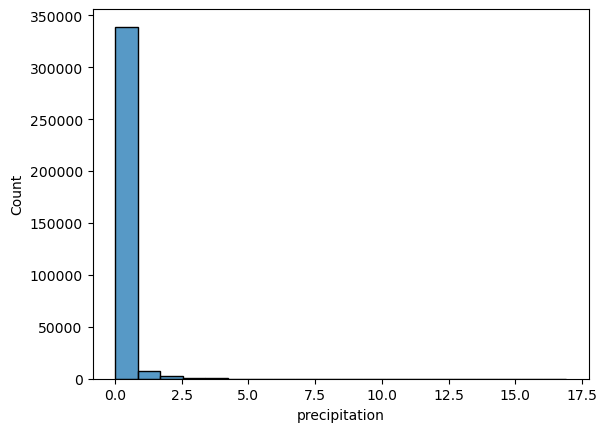

In [23]:
sns.histplot(weather_df['precipitation'], bins=20, kde=False)

<Axes: xlabel='cloud_cover', ylabel='Count'>

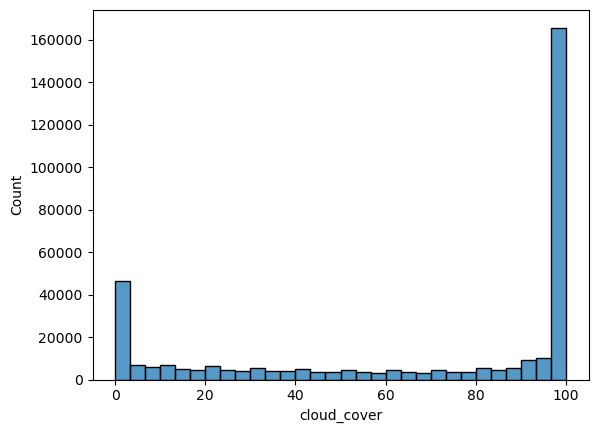

In [25]:
sns.histplot(weather_df['cloud_cover'], bins=30, kde=False)

<Axes: xlabel='relative_humidity_2m', ylabel='Count'>

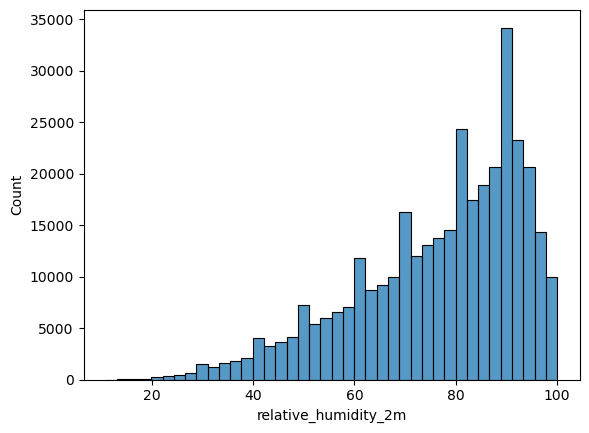

In [27]:
sns.histplot(weather_df['relative_humidity_2m'], bins=40, kde=False)

<Axes: ylabel='Count'>

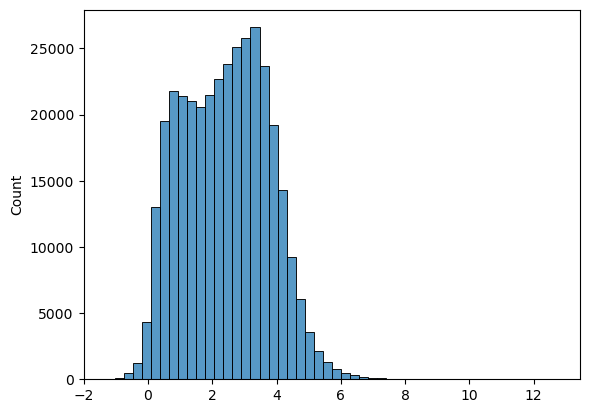

In [31]:
sns.histplot(weather_df['wind_speed_100m'] - weather_df['wind_speed_10m'], bins=50, kde=False)

#### Weather columns shortwave_radiation and precipitation contain values for preceding hour, they need to be shifted to be aligned with generation data

In [20]:
def align_preceding_hour(weather, cols=("shortwave_radiation", "precipitation")):
    """Long-format weather (columns 'time' and 'location', any index): move the preceding-hour
    columns from the END-of-hour label to the START-of-hour label. Value at t+1h becomes the
    value at t, separately for each location. Row order and column order are kept."""
    for needed in ("time", "location"):
        if needed not in weather.columns:
            raise ValueError(f"Column '{needed}' is required")
    cols = [c for c in cols if c in weather.columns]

    out = weather.copy()
    out["time"] = pd.to_datetime(out["time"], utc=True)
    if out.duplicated(["time", "location"]).any():
        raise ValueError("Duplicated (time, location) rows - remove duplicates first.")

    nxt = out[["time", "location"] + cols].copy()           # values keyed by the hour they currently sit on
    nxt["time"] = nxt["time"] - pd.Timedelta(hours=1)        # ...re-keyed one hour EARLIER
    out = out.drop(columns=cols).merge(nxt, on=["time", "location"], how="left")   # look up the value of t+1h
    return out[list(weather.columns)]

In [30]:
weather_df = align_preceding_hour(weather_df)

In [31]:
weather_df.columns

Index(['time', 'location', 'temperature_2m', 'apparent_temperature',
       'relative_humidity_2m', 'precipitation', 'cloud_cover',
       'shortwave_radiation', 'wind_speed_10m', 'wind_speed_100m'],
      dtype='object')

##### Save all clean dataframes into clean csv files

In [33]:
def save_clean_csv(raw_path, clean_df):
    """
    Save a cleaned dataframe to data/clean/<same_filename>.csv

    Rules:
    - raw_path is the original CSV under data/
    - output goes to raw_path.parent / "clean" / raw_path.name
    - if there is a 'time' column, it is moved to the index
    - if the index is already a datetime index, it is kept as-is
    - timestamps are forced to UTC
    """
    raw_path = Path(raw_path)
    if not raw_path.exists():
        raise FileNotFoundError(f"Raw file not found: {raw_path}")

    out_dir = raw_path.parent / "clean"
    out_dir.mkdir(parents=True, exist_ok=True)

    df = clean_df.copy()

    # Make sure time is the index
    if "time" in df.columns:
        df = df.set_index("time")
    elif not isinstance(df.index, pd.DatetimeIndex):
        raise ValueError("DataFrame must have a 'time' column or a DatetimeIndex.")

    # Normalize index to UTC datetime
    try:
        df.index = pd.to_datetime(df.index, utc=True)
    except Exception as e:
        raise ValueError(f"Could not convert index to datetime UTC: {e}") from e

    out_path = out_dir / raw_path.name
    df.to_csv(out_path, index=True)
    print(f"Saved cleaned data to: {out_path}")
    return out_path

In [34]:
# save_clean_csv(grid_load_path, hourly)
# save_clean_csv(generation_path, hourly_generation)
save_clean_csv(weather_path, weather_df)

Saved cleaned data to: ..\data\clean\weather_DE_20210101_20260101.csv


WindowsPath('../data/clean/weather_DE_20210101_20260101.csv')

In [24]:
data_dir = Path("..") / "data"
clean_dir = data_dir / "clean"

grid_load_clean_path = clean_dir / f"grid_load_{COUNTRY}_{START_DATE}_{END_DATE}.csv"
generation_clean_path = clean_dir / f"generation_{COUNTRY}_LU_{START_DATE}_{END_DATE}.csv"
weather_clean_path = clean_dir / f"weather_{COUNTRY}_{START_DATE}_{END_DATE}.csv"

In [35]:
def read_clean_csv_utc(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"{path} not found.")
    df = pd.read_csv(path, index_col=0)
    df.index = pd.to_datetime(df.index, utc=True)
    df.index.name = "time"
    return df

In [36]:
grid_load_df_clean = read_clean_csv_utc(grid_load_clean_path)
generation_df_clean = read_clean_csv_utc(generation_clean_path)
weather_df_clean = read_clean_csv_utc(weather_clean_path)

In [37]:
def average_weather(weather, weights=None, locations=None):
    """
    Average the long-format weather (columns: time, location, <variables>) over locations.

    Parameters
    - weather   : cleaned weather DataFrame ('time' column or index, plus 'location').
    - weights   : optional {location: weight}. Default = every location counts equally.
                  Must contain every location that is used.
    - locations : optional list of locations to use (default: all).

    A location with a NaN in some hour is simply left out of that hour's average (the
    weights of the others are re-normalised), so one missing location does not create
    a NaN in the result.

    Returns a DataFrame indexed by UTC 'time' with one column per weather variable.
    """
    df = weather.reset_index() if "time" not in weather.columns else weather.copy()

    if locations is not None:
        unknown = set(locations) - set(df["location"].unique())
        if unknown:
            raise ValueError(f"Unknown locations: {sorted(unknown)}")
        df = df[df["location"].isin(locations)]

    used = sorted(df["location"].unique())
    if weights is None:
        weights = {loc: 1.0 for loc in used}
    missing = [loc for loc in used if loc not in weights]
    if missing:
        raise ValueError(f"No weight given for locations: {missing}")

    w = df["location"].map(weights).astype(float)
    variables = [c for c in df.columns if c not in ("time", "location")]
    t = df["time"]

    out = {}
    for v in variables:
        x = df[v]
        weighted_sum = (x * w).groupby(t).sum()                    # NaN values are skipped
        weight_sum = w.where(x.notna(), 0.0).groupby(t).sum()      # weights of the locations that have a value
        out[v] = weighted_sum / weight_sum.where(weight_sum > 0)   # no value at all -> NaN
    result = pd.DataFrame(out)
    result.index.name = "time"
    print(f"Averaged {len(variables)} weather variables over {len(used)} locations "
          f"({'weighted' if weights and len(set(weights.values())) > 1 else 'equal weights'}) "
          f"-> {len(result):,} hourly rows")
    return result

##### Average weather data across all locations in Germany

In [38]:
average_weather_df = average_weather(weather_df)
average_weather_df.head(3)

Averaged 8 weather variables over 8 locations (equal weights) -> 43,824 hourly rows


,temperature_2m,apparent_temperature,relative_humidity_2m,precipitation,cloud_cover,shortwave_radiation,wind_speed_10m,wind_speed_100m
time,,,,,,,,
2020-12-31 23:00:00+00:00,1.4250,-2.050,90.750,0.0500,75.625,0.0,2.62625,4.95125
2021-01-01 00:00:00+00:00,1.2625,-2.225,90.875,0.0750,86.875,0.0,2.63250,4.79250
2021-01-01 01:00:00+00:00,0.9250,-2.575,90.750,0.0125,92.000,0.0,2.53875,4.69125


In [39]:
print(grid_load_df_clean.columns)
print(generation_df_clean.columns)
print(average_weather_df.columns)

Index(['Total_Load_MW'], dtype='object')
Index(['Hydro_Pumped_Storage_Consumption_MW', 'Biomass_MW',
       'Fossil_Brown_coal_Lignite_MW', 'Fossil_Gas_MW', 'Fossil_Hard_coal_MW',
       'Fossil_Oil_MW', 'Geothermal_MW', 'Hydro_Pumped_Storage_MW',
       'Hydro_Run_of_river_and_pondage_MW', 'Hydro_Water_Reservoir_MW',
       'Nuclear_MW', 'Other_renewable_MW', 'Solar_MW', 'Waste_MW',
       'Wind_Offshore_MW', 'Wind_Onshore_MW', 'Other_MW'],
      dtype='object')
Index(['temperature_2m', 'apparent_temperature', 'relative_humidity_2m',
       'precipitation', 'cloud_cover', 'shortwave_radiation', 'wind_speed_10m',
       'wind_speed_100m'],
      dtype='object')


In [55]:
def lag_corr(a, b, lags=range(-3, 4)):
    """corr(a(t), b(t+k)) for several shifts k; the peak should be at k=0 if aligned."""
    lag_series = pd.Series({k: a.corr(b.shift(-k)) for k in lags}).round(3)
    df = lag_series.rename_axis("Lag k").reset_index(name="Correlation")
    plt.title("Lag correlation: weather vs generation")
    sns.lineplot(data=df, x="Lag k", y="Correlation", marker="o", color="b")
    plt.show()

    return lag_series

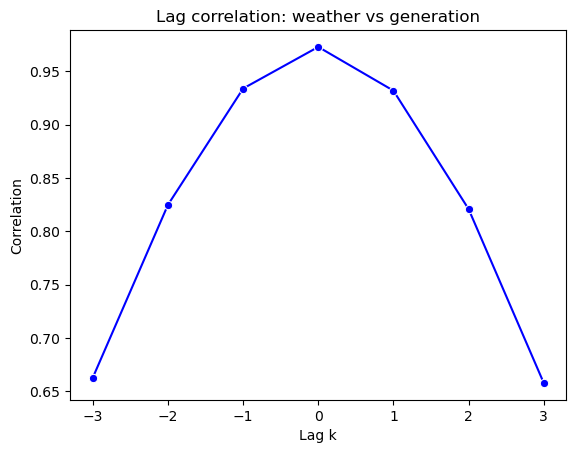

-3    0.663
-2    0.825
-1    0.934
 0    0.973
 1    0.932
 2    0.821
 3    0.658
dtype: float64


In [56]:
lag_series = lag_corr(
    average_weather_df["shortwave_radiation"],
    generation_df_clean["Solar_MW"],
    lags=range(-3, 4)
)
print(lag_series)